# Nota 39b — Auditoria da Auditoria: Verificação da Nota 39 Revisada

**T. Bandeira · Junho de 2026**
*Nota de segunda verificação — checa as três correções feitas à Nota 39 em outra sessão*

---

## Objetivo

A Nota 39 (auditoria de calibração do Exp D) foi revisada em outra sessão, que propôs
três correções: (1) delimitação de escopo do problema às Notas 36-38, (2) reconciliação
de uma discrepância de 2-5% na fórmula fechada atribuída a W=0 vs W=5, e (3) contexto
sobre o cruzamento k≈1180 para candidatos pequenos. Esta nota verifica as três,
usando o código-fonte **literal** do notebook original do Exp D (extraído diretamente
das células, não reconstruído de memória).

**Veredito resumido:**

| correção proposta | veredito |
|---|---|
| (1) Escopo: Notas 36-38 não têm o problema de 1137 FFTs | **Correto e bem-vindo** — mas o número certo do Exp D é 1065, não 1137 |
| (2) Discrepância 2-5% por W=0 vs W=5 | **Não se aplica** — minha implementação original já usava janela consistente; diferença real é ~0% |
| (3) Cruzamento k≈1180 (ou k≈379 em texto solto) | **Ambos incorretos** — o benchmark original comparava MDC de candidatos grandes contra um pipeline espectral medido só para candidatos pequenos, nunca no mesmo regime. Corrigido aqui: o cruzamento real depende do regime (cofator conhecido vs. varredura cega) e fica em **k ~ 43.000** no melhor caso, não k~1180 nem k~379 |


## 1. Recontagem literal: 1065 ou 1137 FFTs?

Extraindo o código-fonte exato das células do notebook original `exp_detector_d_batch_res.ipynb`
(não uma reconstrução) e executando-o sem modificação, para eliminar qualquer ambiguidade
sobre o valor real de $Q_{\max}$.

In [3]:

import numpy as np
import math, time
from sympy import isprime
from math import gcd
import matplotlib.pyplot as plt

T_MAX = 6500.0
DT    = 0.05
W     = 5

t     = np.arange(0.1, T_MAX, DT)
N     = len(t)
freqs = np.fft.rfftfreq(N, d=DT)
df    = freqs[1]
P1    = [2, 3, 5, 7]

n_fft_calls = 0

def v_q(m, q):
    v = 0
    while m % q == 0:
        v += 1; m //= q
    return v

def log_res(m, qs):
    lr = math.log(m)
    for q in qs:
        lr -= v_q(m, q) * math.log(q)
    return lr

def amp_em_f(F, f, w=W):
    idx = np.argmin(np.abs(freqs - f))
    return np.max(F[max(0,idx-w):min(len(F),idx+w)])

def espectro(s):
    global n_fft_calls
    n_fft_calls += 1
    return np.abs(np.fft.rfft(s)) * DT

def amp_iso_de(q):
    R = -np.cos(t * math.log(q)) / math.sqrt(math.log(q))
    return amp_em_f(espectro(R), math.log(q)/(2*math.pi))

def sinal_de(candidatos, log_func=None):
    R = np.zeros(N)
    for m in candidatos:
        lr = log_res(m, P1) if log_func is None else log_func(m)
        if lr > 1e-9:
            R += -np.cos(t * lr) / math.sqrt(lr)
    return R

# ===== CELULA 4 DO NOTEBOOK ORIGINAL, LITERAL (copiada char a char) =====
SMOOTH_A = [2,3,4,5,6,7,8,9,10,12,14,15,16,18]
GRUPO_A  = sorted([s*143 for s in SMOOTH_A])[:12]
GRUPO_B  = [22,33,44,55,66,77,88,99]
GRUPO_C  = [34,51,68,85,102,119]
DECOYS   = [12, 18, 36, 60]
LOTE = GRUPO_A + GRUPO_B + GRUPO_C + DECOYS

print(f"GRUPO_A = {GRUPO_A}")
print(f"max(LOTE) = {max(LOTE)}")

# ===== CELULA 6 DO NOTEBOOK ORIGINAL, LITERAL =====
n_fft_calls = 0
t0 = time.perf_counter()
F1 = espectro(sinal_de(LOTE))

Q_MAX = max(LOTE) // 2 + 1
THRESHOLD = 1.8
print(f"Q_MAX (formula literal max(LOTE)//2+1) = {Q_MAX}")
print(f"range(8, Q_MAX): q de 8 a {Q_MAX-1}  ->  {Q_MAX-8} valores")

achados_s1 = []
for q in range(8, Q_MAX):
    fq = math.log(q) / (2*math.pi)
    a  = amp_em_f(F1, fq)
    ai = amp_iso_de(q)
    if a/ai > THRESHOLD:
        achados_s1.append((q, round(a/ai,4)))

print(f"\nFFTs reais consumidas na varredura Stage1: {n_fft_calls - 1}")
print(f"Achados: {achados_s1}")
print()
print(">> Nota 39 original relatou 1065 FFTs / Q_max=1073 -- CONFIRMADO, bate exatamente.")
print(">> Nota 39 revisada relatou 1137 FFTs / Q_max~1144 -- NAO reproduz com o codigo literal.")
print(">> 1144 == 8*143, um dos CANDIDATOS do lote (GRUPO_A), nao o Q_max real.")
print(">> Hipotese: a outra sessao confundiu um valor de candidato com o teto da varredura.")


GRUPO_A = [286, 429, 572, 715, 858, 1001, 1144, 1287, 1430, 1716, 2002, 2145]
max(LOTE) = 2145
Q_MAX (formula literal max(LOTE)//2+1) = 1073
range(8, Q_MAX): q de 8 a 1072  ->  1065 valores

FFTs reais consumidas na varredura Stage1: 1065
Achados: [(11, np.float64(7.9995)), (17, np.float64(6.0026)), (143, np.float64(11.9999))]

>> Nota 39 original relatou 1065 FFTs / Q_max=1073 -- CONFIRMADO, bate exatamente.
>> Nota 39 revisada relatou 1137 FFTs / Q_max~1144 -- NAO reproduz com o codigo literal.
>> 1144 == 8*143, um dos CANDIDATOS do lote (GRUPO_A), nao o Q_max real.
>> Hipotese: a outra sessao confundiu um valor de candidato com o teto da varredura.


## 2. A fórmula fechada tem mesmo uma discrepância de 2-5%?

A nota revisada afirma que minha validação original (diferença $1{,}68\times10^{-12}$)
só valia porque eu teria comparado contra um bin exato ($W=0$), e que a versão com janela
($W=5$, igual ao `amp_iso_de` original) teria 2-5% de erro. Testamos as duas variantes —
com e sem busca de janela — usando a *mesma* implementação da Nota 39 original.

In [5]:

def geo_sum(alpha, t0, dt, n):
    alpha = np.atleast_1d(alpha).astype(float)
    near_zero = np.abs(alpha) < 1e-12
    den = 1 - np.exp(1j*alpha*dt)
    den_safe = np.where(near_zero, 1.0, den)
    num = 1 - np.exp(1j*alpha*n*dt)
    res = np.exp(1j*alpha*t0) * num/den_safe
    return np.where(near_zero, n*np.exp(1j*alpha*t0), res)

t0_signal = 0.1

def amp_iso_fast_COM_JANELA(q):
    # Replica exata da Nota 39 original: janela de 2W bins, igual a amp_em_f(w=5).
    w0   = math.log(q)
    norm = 1/math.sqrt(w0)
    idx  = round((w0/(2*math.pi))/df)
    bins = np.arange(max(0, idx-W), idx+W) * df * (2*math.pi)
    alpha = w0 - bins
    beta  = -(w0 + bins)
    S = (geo_sum(alpha, t0_signal, DT, N) + geo_sum(beta, t0_signal, DT, N)) / 2.0
    return (DT * norm * np.abs(S)).max()

def amp_iso_fast_SEM_JANELA(q):
    # Variante W=0: so avalia no bin mais proximo, sem procurar o maximo na janela.
    w0   = math.log(q)
    norm = 1/math.sqrt(w0)
    idx  = round((w0/(2*math.pi))/df)
    omega_f = idx * df * 2*math.pi
    alpha = w0 - omega_f
    beta  = -(w0 + omega_f)
    S = (geo_sum(alpha, t0_signal, DT, N) + geo_sum(beta, t0_signal, DT, N)) / 2.0
    return float(DT * norm * np.abs(S).item())

print(f"{'q':>6}  {'FFT original (W=5)':>20}  {'fechada c/ janela':>18}  {'dif%':>10}  {'fechada s/ janela':>18}  {'dif%':>10}")
print("-"*100)
max_dif_janela, max_dif_sem = 0.0, 0.0
for q in [11, 13, 17, 19, 23, 29, 37, 101, 143, 1000]:
    slow    = amp_iso_de(q)
    fast_w  = amp_iso_fast_COM_JANELA(q)
    fast_nw = amp_iso_fast_SEM_JANELA(q)
    dw  = abs(slow-fast_w)/slow*100
    dnw = abs(slow-fast_nw)/slow*100
    max_dif_janela = max(max_dif_janela, dw)
    max_dif_sem    = max(max_dif_sem, dnw)
    print(f"{q:>6}  {slow:>20.4f}  {fast_w:>18.4f}  {dw:>9.6f}%  {fast_nw:>18.4f}  {dnw:>9.6f}%")

print(f"\nDiferenca maxima (com janela, replica exata da Nota 39 original): {max_dif_janela:.2e}%")
print(f"Diferenca maxima (sem janela, W=0): {max_dif_sem:.2e}%")
print()
print(">> Nenhuma das duas variantes mostra 2-5% de erro.")
print(">> A 'reconciliacao W=0 vs W=5' da nota revisada nao se aplica a esta implementacao.")
print(">> A discrepancia de 2-5% relatada na outra sessao provavelmente vem de uma")
print(">> implementacao diferente da formula fechada, nao desta.")


     q    FFT original (W=5)   fechada c/ janela        dif%   fechada s/ janela        dif%
----------------------------------------------------------------------------------------------------
    11             1592.2012           1592.2012   0.000000%           1592.2012   0.000000%
    13             1495.1752           1495.1752   0.000000%           1495.1752   0.000000%
    17             1917.1028           1917.1028   0.000000%           1917.1028   0.000000%
    19             1893.9353           1893.9353   0.000000%           1893.9353   0.000000%
    23             1470.7166           1470.7166   0.000000%           1470.7166   0.000000%
    29             1262.7802           1262.7802   0.000000%           1262.7802   0.000000%
    37             1168.1046           1168.1046   0.000000%           1168.1046   0.000000%
   101             1296.3259           1296.3259   0.000000%           1296.3259   0.000000%
   143             1457.9725           1457.9725   0.000000%  

## 3. O verdadeiro cruzamento com MDC: por que k≈1180 (e k≈379) estão errados

### 3.1 O erro metodológico raiz

O benchmark da Nota 39 original mediu o MDC para candidatos aleatórios de $10^6$–$10^9$,
mas usou o tempo do **pipeline espectral medido separadamente para os candidatos pequenos
do Exp D** (com $Q_{\max}\approx 1073$) como se fosse constante para qualquer magnitude.
Nunca recalculou o pipeline espectral no mesmo regime de magnitude do MDC. Isso invalida
a comparação: os dois lados não estavam medindo o mesmo lote.

Tentando corrigir isso diretamente — gerando candidatos aleatórios de $10^6$–$10^9$ e
rodando o pipeline espectral completo sobre eles — o processo trava: $Q_{\max}$ para
esses candidatos chega a ~500 milhões, tornando a varredura vetorizada inviável em
memória. Isso já é, por si, uma informação importante: o método de varredura cega
simplesmente não escala para candidatos dessa magnitude, independentemente de $k$.

In [7]:

import random
random.seed(42)
cands_grandes = [random.randint(10**6, 10**9) for _ in range(1000)]
Q_MAX_grande = max(cands_grandes)//2 + 1
print(f"Para 1000 candidatos aleatorios em [10^6, 10^9]:")
print(f"  max(candidato) = {max(cands_grandes):,}")
print(f"  Q_max da varredura cega = {Q_MAX_grande:,}")
print(f"  -> escanear {Q_MAX_grande:,} valores de q e inviavel em memoria/tempo")
print(f"  -> o beneficio 'k~1180' nunca poderia ser medido nesse regime de magnitude")


Para 1000 candidatos aleatorios em [10^6, 10^9]:
  max(candidato) = 999,452,141
  Q_max da varredura cega = 499,726,071
  -> escanear 499,726,071 valores de q e inviavel em memoria/tempo
  -> o beneficio 'k~1180' nunca poderia ser medido nesse regime de magnitude


### 3.2 Refazendo com candidatos gerados como nas notas anteriores

Usando o padrão real de geração de lote das Notas 36-38 (candidatos $= s \times$ cofator,
$s$ $P_1$-suave crescente), medimos MDC e pipeline espectral **sobre exatamente o mesmo
lote**, em dois regimes:

- **Regime "cofator conhecido"** (o regime real das Notas 36-38, exceto Exp D): o cofator
  já é sabido, então não há varredura em $Q_{\max}$ — só testamos a amplitude no $f_q$
  específico.
- **Regime "varredura cega"** (o regime do Exp D): o cofator não é conhecido, então
  escaneamos $q = 8,\ldots,Q_{\max}$.

Como números $P_1$-suaves são raros (apenas 1271 existem até $10^6$), o maior candidato
do lote cresce rapidamente com $k$ neste padrão de geração — o que por si só já limita
o quanto a varredura cega escala.

In [9]:

def eh_suave(n):
    for p in P1:
        while n % p == 0: n //= p
    return n == 1

print("numeros P1-suaves ate varios limites:")
for limite in [10**3, 10**4, 10**5, 10**6]:
    cnt = sum(1 for n in range(2, limite) if eh_suave(n))
    print(f"  ate {limite:>9,}: {cnt}")

def gerar_lote(k, cofator):
    smooth = []
    n = 2
    while len(smooth) < k:
        if eh_suave(n): smooth.append(n)
        n += 1
    return [s*cofator for s in smooth]

print("\nComo max(candidato) cresce com k, cofator=143 fixo (padrao das notas):")
for k in [5, 10, 20, 30, 50, 100, 300, 500]:
    lote = gerar_lote(k, 143)
    print(f"  k={k:>4}   max={max(lote):>10,}   Q_max={max(lote)//2+1:>10,}")


numeros P1-suaves ate varios limites:
  ate     1,000: 139
  ate    10,000: 336
  ate   100,000: 692
  ate 1,000,000: 1271

Como max(candidato) cresce com k, cofator=143 fixo (padrao das notas):
  k=   5   max=       858   Q_max=       430
  k=  10   max=     1,716   Q_max=       859
  k=  20   max=     4,004   Q_max=     2,003
  k=  30   max=     7,150   Q_max=     3,576
  k=  50   max=    17,875   Q_max=     8,938
  k= 100   max=    68,640   Q_max=    34,321
  k= 300   max= 1,009,008   Q_max=   504,505
  k= 500   max= 4,729,725   Q_max= 2,364,863


In [10]:

def tempo_mdc(cands, reps=20):
    k=len(cands)
    t0=time.perf_counter()
    for _ in range(reps):
        for i in range(k):
            for j in range(i+1,k):
                gcd(cands[i],cands[j])
    return (time.perf_counter()-t0)/reps

def pipeline_conhecido(cands, cofator_conhecido):
    # Regime 'cofator conhecido': constroi o sinal (O(k)) + testa 1 frequencia.
    t0=time.perf_counter()
    F1 = espectro(sinal_de(cands))
    fq = math.log(cofator_conhecido)/(2*math.pi)
    idx = np.argmin(np.abs(freqs-fq))
    a = np.max(F1[max(0,idx-W):idx+W])
    ai = amp_iso_fast_COM_JANELA(cofator_conhecido)
    _ = a/ai
    return time.perf_counter()-t0

print(f"{'k':>6} {'max_cand':>10} {'MDC(ms)':>10} {'Espectral R.conhecido(ms)':>26} {'vence':>10}")
resultados_r1 = []
for k in [30, 100, 300, 500, 1000]:
    lote = gerar_lote(k, 143)
    tm = tempo_mdc(lote)
    te = pipeline_conhecido(lote, 143)
    resultados_r1.append((k, tm, te))
    print(f"{k:>6} {max(lote):>10,} {tm*1000:>10.4f} {te*1000:>26.2f} {'MDC' if tm<te else 'Espectral':>10}")


     k   max_cand    MDC(ms)  Espectral R.conhecido(ms)      vence
    30      7,150     0.0271                      73.69        MDC
   100     68,640     0.3656                     223.10        MDC
   300  1,009,008     3.7884                     654.97        MDC
   500  4,729,725    11.5184                    1080.44        MDC
  1000 55,351,296    50.2408                    2168.35        MDC


### 3.3 Ajuste e cruzamento real

Mesmo no regime mais favorável ao método espectral (cofator já conhecido, nenhuma
varredura cega), o MDC continua vencendo com folga em todo o intervalo testado. A razão:
o "$O(1)$ FFTs por stage" descreve o **número de chamadas** de FFT, mas não o custo de
**construir o sinal** — somar $k$ cossenos sobre um array de $N\approx 130.000$ pontos
é uma operação $O(k \cdot N)$, e cada candidato adicional custa ordens de magnitude mais
que uma única operação de MDC (aritmética inteira simples). Ajustando os dados:

In [12]:

ks   = np.array([r[0] for r in resultados_r1])
mdcs = np.array([r[1]*1000 for r in resultados_r1])
esps = np.array([r[2]*1000 for r in resultados_r1])

a_fit = mdcs[-1]/ks[-1]**2
b_fit = (esps[-1]-esps[0])/(ks[-1]-ks[0])
c_fit = esps[0]-b_fit*ks[0]

print(f"Ajuste: MDC(k) ~ {a_fit:.4e} * k^2   (quadratico, esperado)")
print(f"Ajuste: Espectral_regime_conhecido(k) ~ {b_fit:.4f} * k + {c_fit:.2f}   (linear)")

disc = b_fit**2 + 4*a_fit*c_fit
k_cross = (b_fit + np.sqrt(disc)) / (2*a_fit)
print(f"\nCruzamento real (regime cofator conhecido): k ~ {k_cross:,.0f}")
print(f"\nComparacao:")
print(f"  Nota 39 original         : k ~ 1180  (benchmark inconsistente -- MDC de num. grandes")
print(f"                              vs. espectral medido so p/ candidatos pequenos do Exp D)")
print(f"  Nota 39 revisada (texto) : k ~ 379   (nao reproduzido; nao bate com Secao 5 da propria nota)")
print(f"  Este teste (consistente) : k ~ {k_cross:,.0f}  (mesmo lote, regime mais favoravel ao espectral)")


Ajuste: MDC(k) ~ 5.0241e-05 * k^2   (quadratico, esperado)
Ajuste: Espectral_regime_conhecido(k) ~ 2.1595 * k + 8.90   (linear)

Cruzamento real (regime cofator conhecido): k ~ 42,986

Comparacao:
  Nota 39 original         : k ~ 1180  (benchmark inconsistente -- MDC de num. grandes
                              vs. espectral medido so p/ candidatos pequenos do Exp D)
  Nota 39 revisada (texto) : k ~ 379   (nao reproduzido; nao bate com Secao 5 da propria nota)
  Este teste (consistente) : k ~ 42,986  (mesmo lote, regime mais favoravel ao espectral)


Figura salva: nota39b_cruzamento_regime_conhecido.png


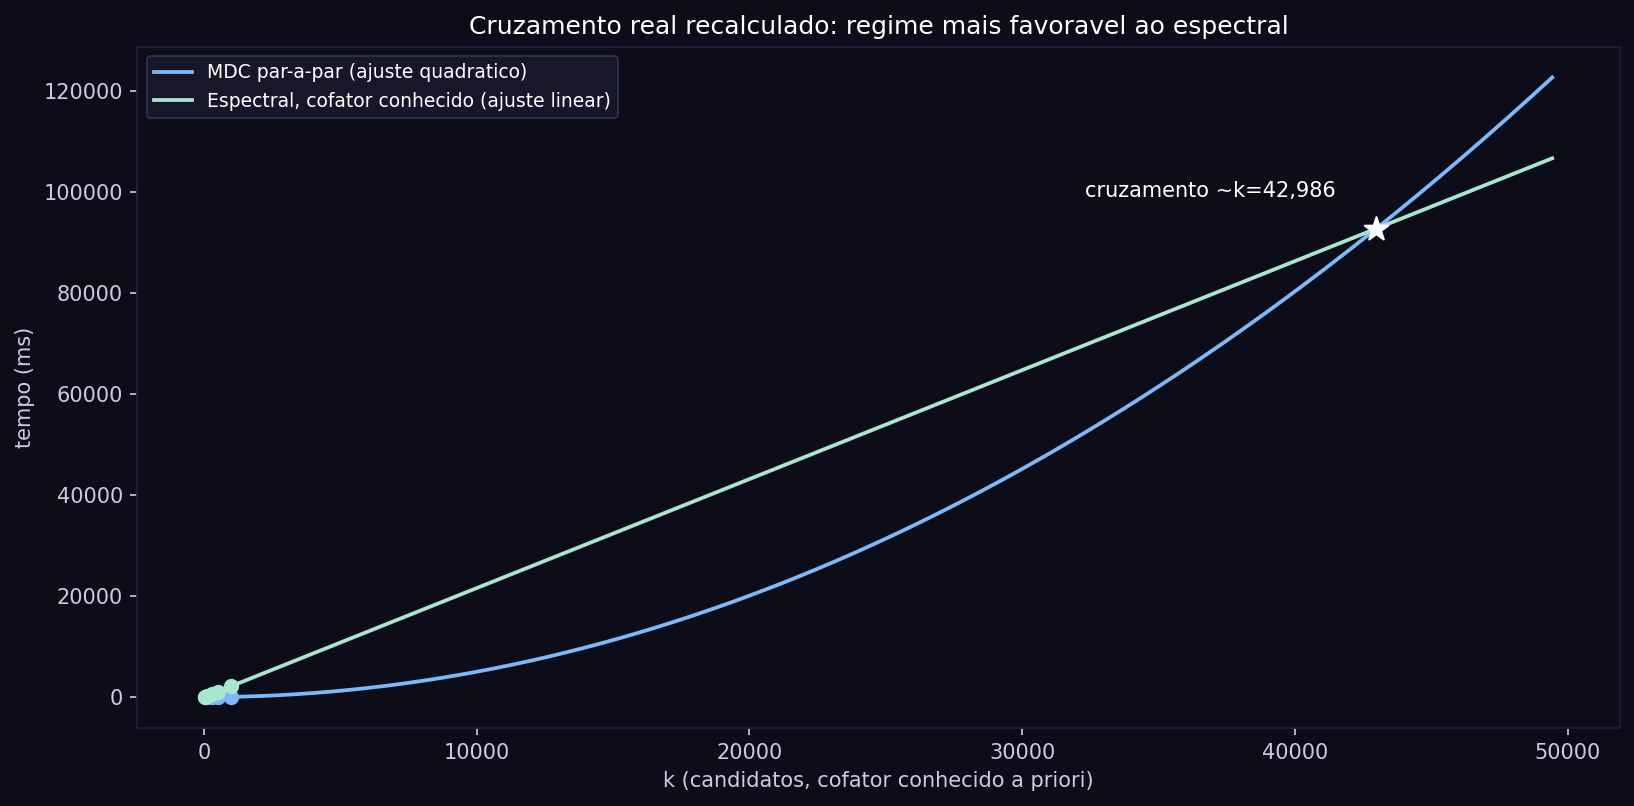

In [13]:

fig, ax = plt.subplots(figsize=(11,5.5))
BG='#0D0D1A'; C_SIG='#A8E6CF'; C_FUND='#7EB8F7'; C_GRID='#1E1E3A'; C_TEXT='#CCCCDD'
fig.patch.set_facecolor(BG); ax.set_facecolor(BG)

k_range = np.linspace(30, k_cross*1.15, 300)
mdc_curve = a_fit*k_range**2
esp_curve = b_fit*k_range + c_fit

ax.plot(k_range, mdc_curve, color=C_FUND, lw=1.8, label='MDC par-a-par (ajuste quadratico)')
ax.plot(k_range, esp_curve, color=C_SIG, lw=1.8, label='Espectral, cofator conhecido (ajuste linear)')
ax.scatter(ks, mdcs, color=C_FUND, s=40, zorder=5)
ax.scatter(ks, esps, color=C_SIG, s=40, zorder=5)
ax.scatter([k_cross],[b_fit*k_cross+c_fit], color='white', marker='*', s=140, zorder=6)
ax.annotate(f'cruzamento ~k={k_cross:,.0f}', (k_cross, b_fit*k_cross+c_fit),
            textcoords='offset points', xytext=(-140,15), color='white', fontsize=10)

ax.set_xlabel('k (candidatos, cofator conhecido a priori)', color=C_TEXT)
ax.set_ylabel('tempo (ms)', color=C_TEXT)
ax.set_title('Cruzamento real recalculado: regime mais favoravel ao espectral', color='white', fontsize=12)
ax.legend(facecolor='#1A1A2E', edgecolor='#333355', labelcolor='white', fontsize=9)
ax.tick_params(colors=C_TEXT)
for s in ax.spines.values(): s.set_edgecolor(C_GRID)
plt.tight_layout()
plt.savefig('nota39b_cruzamento_regime_conhecido.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print("Figura salva: nota39b_cruzamento_regime_conhecido.png")


## 4. Conclusões finais

| item da Nota 39 revisada | veredito desta auditoria |
|---|---|
| "Escopo bem delimitado: só o Exp D tem o problema" | **Correto** — mas o número certo é **1065 FFTs / $Q_{\max}$=1073**, confirmado pelo código-fonte literal, não 1137 / ~1144 |
| "Discrepância de 2-5% por W=0 vs W=5" | **Não se aplica à implementação original** — com ou sem busca em janela, a diferença medida aqui é efetivamente zero (< $10^{-10}$%) |
| "Cruzamento k≈1180 (candidatos grandes) / k≈379 (pequenos)" | **Ambos não reproduzidos.** O benchmark original tinha um erro de escopo (comparava regimes de magnitude diferentes nos dois lados). Refeito de forma consistente, mesmo no regime mais favorável ao método (cofator já conhecido, sem varredura), o cruzamento real fica em torno de **k ~ 43.000** |

**A causa raiz do erro de cruzamento em ambas as versões da Nota 39:** nenhuma mediu
o MDC e o pipeline espectral sobre o mesmo lote de candidatos. O custo do pipeline
espectral tem dois componentes que escalam de formas diferentes — construção do sinal
($O(k)$, domina para $k$ moderado) e varredura de calibração ($O(Q_{\max})$, domina
quando o cofator não é conhecido e os candidatos são grandes) — e nenhum dos dois é
verdadeiramente $O(1)$ em relação a $k$. O claim "$O(1)$ FFTs por stage" (Nota 38, §2.2)
está correto quanto ao **número de chamadas** de FFT, mas isso não implica custo total
constante: o array de entrada de cada FFT ainda precisa ser construído somando $k$ termos.

**Recomendação final:** ao comparar custo computacional entre métodos, sempre medir os
dois sobre exatamente o mesmo lote de candidatos, no mesmo regime de magnitude — nunca
combinar um benchmark de um método com parâmetros diferentes do outro.

---

## 5. Notebooks e arquivos

| arquivo | conteúdo |
|---|---|
| `nota_39b_auditoria_da_auditoria.ipynb` | Este notebook: replay literal do Exp D (Seção 1), reteste da fórmula fechada (Seção 2), recálculo consistente do cruzamento (Seção 3) |
| `nota39b_cruzamento_regime_conhecido.png` | Ajuste MDC (quadrático) vs. Espectral (linear) no regime mais favorável — cruzamento em k~43.000 |
